# exploration des données

## 1- Import Libraries

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

#charte graphique pour les plots
import seaborn as sns
from charte_graphique import BLEU, ROUGE, BLANC, GRIS, appliquer_charte, teintes, CMAP_DIV
appliquer_charte()

#fix random grains
#Seed = reproductibilité des expériences.
def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)
set_seed(0)


## 2- Load datasets

In [5]:
DATA_DIR = "../data/raw_har_data"
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
test_df  = pd.read_csv(f"{DATA_DIR}/test.csv")


## 3- Exploration

### 3.1 afficher le nombre d’observations, de variables et de volontaires

In [6]:
#colonne : subject ->	Identifiant du participant	->Exclue des features
#          Activity ->	Activité réalisée (Walking, Sitting...)	-> Target (à prédire)

feature_cols = [c for c in train_df.columns if c not in ("subject", "Activity")]
print("train  dataset :", train_df.shape, "| test dataset:", test_df.shape)

#feature_cols contient les colonnes restantes après exclusion de subject et Activity
print("nombre de variables(features(X)) :", len(feature_cols))

print("trois dernières colonnes :", list(train_df.columns[-3:]))

train_df.head()

train  dataset : (7352, 563) | test dataset: (2947, 563)
nombre de variables(features(X)) : 561
trois dernières colonnes : ['angle(Z,gravityMean)', 'subject', 'Activity']


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


In [9]:
train_df.columns

Index(['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z',
       'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z',
       'tBodyAcc-mad()-X', 'tBodyAcc-mad()-Y', 'tBodyAcc-mad()-Z',
       'tBodyAcc-max()-X',
       ...
       'fBodyBodyGyroJerkMag-kurtosis()', 'angle(tBodyAccMean,gravity)',
       'angle(tBodyAccJerkMean),gravityMean)',
       'angle(tBodyGyroMean,gravityMean)',
       'angle(tBodyGyroJerkMean,gravityMean)', 'angle(X,gravityMean)',
       'angle(Y,gravityMean)', 'angle(Z,gravityMean)', 'subject', 'Activity'],
      dtype='str', length=563)

On vérifie aussi que les volontaires du test ne figurent pas dans le train (c'est ce qui rend l'évaluation réaliste), et qu'il n'y a ni valeur manquante ni ligne dupliquée.

In [4]:
for name, df in [("train", train_df), ("test", test_df)]:
    print(f"{name} : {len(df)} observations | {df.shape[1] - 2} variables | {df['subject'].nunique()} volontaires")

print("volontaires train :", sorted(train_df["subject"].unique().tolist()))
print("volontaires test  :", sorted(test_df["subject"].unique().tolist()))

print("volontaires communs aux deux fichiers :", set(train_df["subject"].tolist()) & set(test_df["subject"].tolist()))


train : 7352 observations | 561 variables | 21 volontaires
test : 2947 observations | 561 variables | 9 volontaires
volontaires train : [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
volontaires test  : [2, 4, 9, 10, 12, 13, 18, 20, 24]
volontaires communs aux deux fichiers : set()


In [5]:
#values manquantes  dans les eux jeux de données
print("valeurs manquantes (train, test) :", train_df.isna().sum().sum(), test_df.isna().sum().sum())


valeurs manquantes (train, test) : 0 0


In [6]:
# dedoublement des lignes dans le jeu de données train
print("lignes dupliquées (train) :", train_df.duplicated().sum())

lignes dupliquées (train) : 0


In [7]:
#  vérifier le type de données que ça soit tous numériques
non_numeric_features = [c for c in feature_cols if not np.issubdtype(train_df[c].dtype, np.number)]
print(f"Non-numeric feature columns: {len(non_numeric_features)}")

Non-numeric feature columns: 0


**Remarques**: Le fichier d'entraînement **"train"** contient 7352 observations, 561 variables et 21 volontaires. Le fichier de **"test"** contient 2947 observations, 561 variables et 9 volontaires. Il n'y a aucune valeur manquante, aucune ligne dupliquée et aucune colonne non numérique.

Aucun volontaire n'apparaît dans les deux fichiers (intersection vide). C'est important car le test doit mesurer la capacité du modèle à **généraliser à des personnes qu'il n'a jamais vues**, ce qui est le cas d'usage réel. Si une même personne se trouvait dans les deux fichiers, le modèle pourrait reconnaître sa façon de bouger plutôt que l'activité, et le score de test serait trop optimiste.

### 3.2 Distribution des classes
Le nombre de fenêtres par classe d'activités (et par volontaire) dans les datasets Train et Test, conditionne le choix des métriques : accuracy ou F1.

findfont: Failed to find font weight semibold for Arial, now using 700.


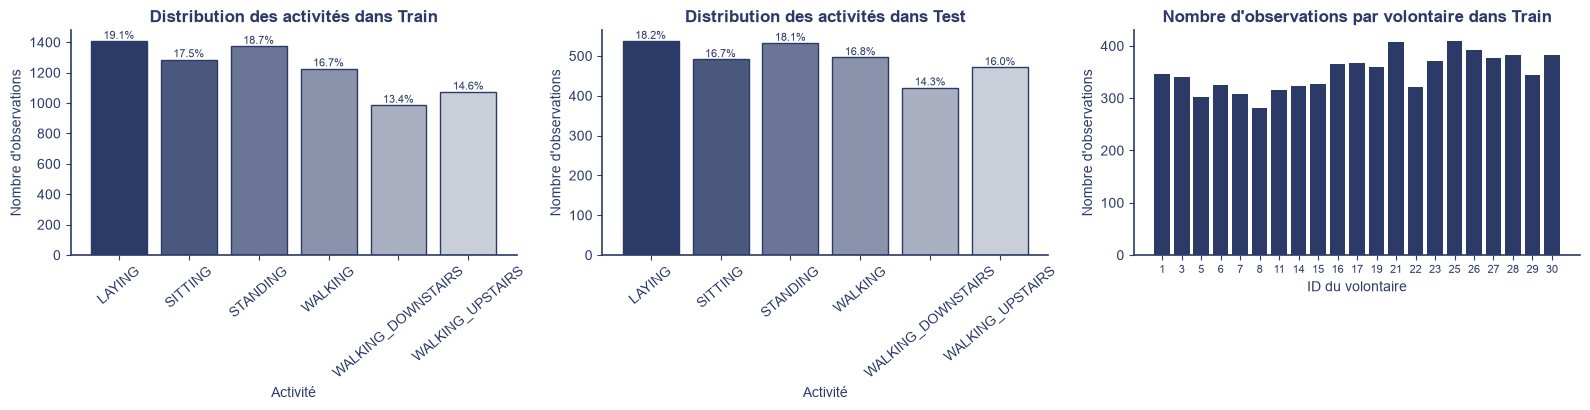

In [8]:
# Extraire les différentes classes d'activités sans répétition, puis les trier par ordre alphabétique
classes = sorted(train_df["Activity"].unique())

# 3 graphiques : distribution des activités dans Train, dans Test,
# et nombre d'observations par volontaire dans Train
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

for ax, (name, df) in zip(axes[:2], [("Train", train_df), ("Test", test_df)]):
    # Nombre d'observations par activité, rangées dans l'ordre des classes
    counts = df["Activity"].value_counts().reindex(classes)
    ax.bar(classes, counts.values, color=teintes(len(classes)), edgecolor=BLEU)
    ax.set_title(f"Distribution des activités dans {name}")
    ax.set_xlabel("Activité"); ax.set_ylabel("Nombre d'observations")
    ax.tick_params(axis="x", labelrotation=40)
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v / len(df):.1%}", ha="center", va="bottom", fontsize=8)

# Nombre d'observations par volontaire (identifiant = colonne "subject")
per_volunteer = train_df["subject"].value_counts().sort_index()
axes[2].bar(per_volunteer.index.astype(str), per_volunteer.values, color=BLEU)
axes[2].set_title("Nombre d'observations par volontaire dans Train")
axes[2].set_xlabel("ID du volontaire"); axes[2].set_ylabel("Nombre d'observations")
axes[2].tick_params(axis="x", labelsize=8)

plt.tight_layout(); plt.show()

**Remarques** — Les classes sont à peu près équilibrées. Aucune classe n'est rare ni dominante : la répartition idéale serait 16,7 % chacune.

Les proportions sont très proches entre train et test (par exemple LAYING 19,1 % contre 18,2 %, WALKING_DOWNSTAIRS 13,4 % contre 14,3 %). Les classes les plus et les moins fréquentes sont les mêmes dans les deux fichiers, et les écarts restent inférieurs à 1 point. La distribution observée à l'entraînement est donc représentative de celle du test.

**Conséquence pour les métriques** : comme le déséquilibre est modéré, l'accuracy reste interprétable (un modèle qui prédit toujours LAYING n'obtiendrait qu'environ 19 %) et elle sera proche du F1 macro. Le F1 macro reste néanmoins plus informatif, parce qu'il donne le même poids à chaque classe, y compris aux moins fréquentes, et que le F1 par classe permet de repérer les activités difficiles (typiquement SITTING et STANDING), ce que l'accuracy globale masque. On utilisera donc les deux métriques, en s'appuyant sur le F1 macro et le F1 par classe pour comparer les modèles.

### 3.3 Statistiques descriptives


In [9]:
# Statistiques de chaque variable : mean, std, min, max en lignes, variables en colonnes
stats = train_df[feature_cols].describe().loc[["mean", "std", "min", "max"]]

pd.set_option("display.max_columns", None)    # afficher toutes les colonnes
display(stats.round(3))

# Résumé sur les 561 variables
print("moyennes     : de", stats.loc["mean"].min().round(3), "à", stats.loc["mean"].max().round(3))
print("écart-types  : de", stats.loc["std"].min().round(3), "à", stats.loc["std"].max().round(3))
print("minimum      :", stats.loc["min"].min().round(3), "| maximum :", stats.loc["max"].max().round(3))

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,tBodyAcc-max()-Y,tBodyAcc-max()-Z,tBodyAcc-min()-X,tBodyAcc-min()-Y,tBodyAcc-min()-Z,tBodyAcc-sma(),tBodyAcc-energy()-X,tBodyAcc-energy()-Y,tBodyAcc-energy()-Z,tBodyAcc-iqr()-X,tBodyAcc-iqr()-Y,tBodyAcc-iqr()-Z,tBodyAcc-entropy()-X,tBodyAcc-entropy()-Y,tBodyAcc-entropy()-Z,"tBodyAcc-arCoeff()-X,1","tBodyAcc-arCoeff()-X,2","tBodyAcc-arCoeff()-X,3","tBodyAcc-arCoeff()-X,4","tBodyAcc-arCoeff()-Y,1","tBodyAcc-arCoeff()-Y,2","tBodyAcc-arCoeff()-Y,3","tBodyAcc-arCoeff()-Y,4","tBodyAcc-arCoeff()-Z,1","tBodyAcc-arCoeff()-Z,2","tBodyAcc-arCoeff()-Z,3","tBodyAcc-arCoeff()-Z,4","tBodyAcc-correlation()-X,Y","tBodyAcc-correlation()-X,Z","tBodyAcc-correlation()-Y,Z",tGravityAcc-mean()-X,tGravityAcc-mean()-Y,tGravityAcc-mean()-Z,tGravityAcc-std()-X,tGravityAcc-std()-Y,tGravityAcc-std()-Z,tGravityAcc-mad()-X,tGravityAcc-mad()-Y,tGravityAcc-mad()-Z,tGravityAcc-max()-X,tGravityAcc-max()-Y,tGravityAcc-max()-Z,tGravityAcc-min()-X,tGravityAcc-min()-Y,tGravityAcc-min()-Z,tGravityAcc-sma(),tGravityAcc-energy()-X,tGravityAcc-energy()-Y,tGravityAcc-energy()-Z,tGravityAcc-iqr()-X,tGravityAcc-iqr()-Y,tGravityAcc-iqr()-Z,tGravityAcc-entropy()-X,tGravityAcc-entropy()-Y,tGravityAcc-entropy()-Z,"tGravityAcc-arCoeff()-X,1","tGravityAcc-arCoeff()-X,2","tGravityAcc-arCoeff()-X,3","tGravityAcc-arCoeff()-X,4","tGravityAcc-arCoeff()-Y,1","tGravityAcc-arCoeff()-Y,2","tGravityAcc-arCoeff()-Y,3","tGravityAcc-arCoeff()-Y,4","tGravityAcc-arCoeff()-Z,1","tGravityAcc-arCoeff()-Z,2","tGravityAcc-arCoeff()-Z,3","tGravityAcc-arCoeff()-Z,4","tGravityAcc-correlation()-X,Y","tGravityAcc-correlation()-X,Z","tGravityAcc-correlation()-Y,Z",tBodyAccJerk-mean()-X,tBodyAccJerk-mean()-Y,tBodyAccJerk-mean()-Z,tBodyAccJerk-std()-X,tBodyAccJerk-std()-Y,tBodyAccJerk-std()-Z,tBodyAccJerk-mad()-X,tBodyAccJerk-mad()-Y,tBodyAccJerk-mad()-Z,tBodyAccJerk-max()-X,tBodyAccJerk-max()-Y,tBodyAccJerk-max()-Z,tBodyAccJerk-min()-X,tBodyAccJerk-min()-Y,tBodyAccJerk-min()-Z,tBodyAccJerk-sma(),tBodyAccJerk-energy()-X,tBodyAccJerk-energy()-Y,tBodyAccJerk-energy()-Z,tBodyAccJerk-iqr()-X,tBodyAccJerk-iqr()-Y,tBodyAccJerk-iqr()-Z,tBodyAccJerk-entropy()-X,tBodyAccJerk-entropy()-Y,tBodyAccJerk-entropy()-Z,"tBodyAccJerk-arCoeff()-X,1","tBodyAccJerk-arCoeff()-X,2","tBodyAccJerk-arCoeff()-X,3","tBodyAccJerk-arCoeff()-X,4","tBodyAccJerk-arCoeff()-Y,1","tBodyAccJerk-arCoeff()-Y,2","tBodyAccJerk-arCoeff()-Y,3","tBodyAccJerk-arCoeff()-Y,4","tBodyAccJerk-arCoeff()-Z,1","tBodyAccJerk-arCoeff()-Z,2","tBodyAccJerk-arCoeff()-Z,3","tBodyAccJerk-arCoeff()-Z,4","tBodyAccJerk-correlation()-X,Y","tBodyAccJerk-correlation()-X,Z","tBodyAccJerk-correlation()-Y,Z",tBodyGyro-mean()-X,tBodyGyro-mean()-Y,tBodyGyro-mean()-Z,tBodyGyro-std()-X,tBodyGyro-std()-Y,tBodyGyro-std()-Z,tBodyGyro-mad()-X,tBodyGyro-mad()-Y,tBodyGyro-mad()-Z,tBodyGyro-max()-X,tBodyGyro-max()-Y,tBodyGyro-max()-Z,tBodyGyro-min()-X,tBodyGyro-min()-Y,tBodyGyro-min()-Z,tBodyGyro-sma(),tBodyGyro-energy()-X,tBodyGyro-energy()-Y,tBodyGyro-energy()-Z,tBodyGyro-iqr()-X,tBodyGyro-iqr()-Y,tBodyGyro-iqr()-Z,tBodyGyro-entropy()-X,tBodyGyro-entropy()-Y,tBodyGyro-entropy()-Z,"tBodyGyro-arCoeff()-X,1","tBodyGyro-arCoeff()-X,2","tBodyGyro-arCoeff()-X,3","tBodyGyro-arCoeff()-X,4","tBodyGyro-arCoeff()-Y,1","tBodyGyro-arCoeff()-Y,2","tBodyGyro-arCoeff()-Y,3","tBodyGyro-arCoeff()-Y,4","tBodyGyro-arCoeff()-Z,1","tBodyGyro-arCoeff()-Z,2","tBodyGyro-arCoeff()-Z,3","tBodyGyro-arCoeff()-Z,4","tBodyGyro-correlation()-X,Y","tBodyGyro-correlation()-X,Z","tBodyGyro-correlation()-Y,Z",tBodyGyroJerk-mean()-X,tBodyGyroJerk-mean()-Y,tBodyGyroJerk-mean()-Z,tBodyGyroJerk-std()-X,tBodyGyroJerk-std()-Y,tBodyGyroJerk-std()-Z,tBodyGyroJerk-mad()-X,tBodyGyroJerk-mad()-Y,tBodyGyroJerk-mad()-Z,tBodyGyroJerk-max()-X,tBodyGyroJerk-max()-Y,tBodyGyroJerk-max()-Z,tBodyGyroJerk-min()-X,tBodyGyroJerk-min()-Y,tBodyGyroJerk-min()-Z,tBodyGyroJ

moyennes     : de -0.984 à 0.83
écart-types  : de 0.041 à 0.752
minimum      : -1.0 | maximum : 1.0


**Remarques** : Les variables sont déjà **mises à l'échelle** par les auteurs du jeu de données : sur les 561 variables, les valeurs sont toutes comprises dans l'intervalle [-1, 1].

Elles ne sont en revanche **pas centrées et réduites**.  certaines variables sont très concentrées (écart-type d'environ 0,04), d'autres très dispersées (écart-type d'environ 0,5). Une même plage [-1, 1] ne donne donc pas la même dispersion d'une variable à l'autre.

**Pourquoi cela compte pour l'optimisation** : quand les variables ont des échelles différentes, la surface de la perte est très étirée dans certaines directions : c'est une **ravine** (mauvais conditionnement). Le gradient pointe alors surtout vers les côtés de la ravine plutôt que vers le minimum. Avec un pas d'apprentissage assez grand pour avancer dans la direction plate, la descente oscille d'un bord à l'autre ; avec un pas assez petit pour être stable, elle progresse très lentement. Une même valeur du pas ne convient pas à toutes les variables. Centrer et réduire chaque variable rend la surface plus régulière : le gradient pointe plus directement vers le minimum, le pas peut être plus grand, et la convergence est plus rapide et plus stable. **On standardisera donc les variables (moyenne et écart-type calculés sur le train uniquement) à l'étape preprocessing**.

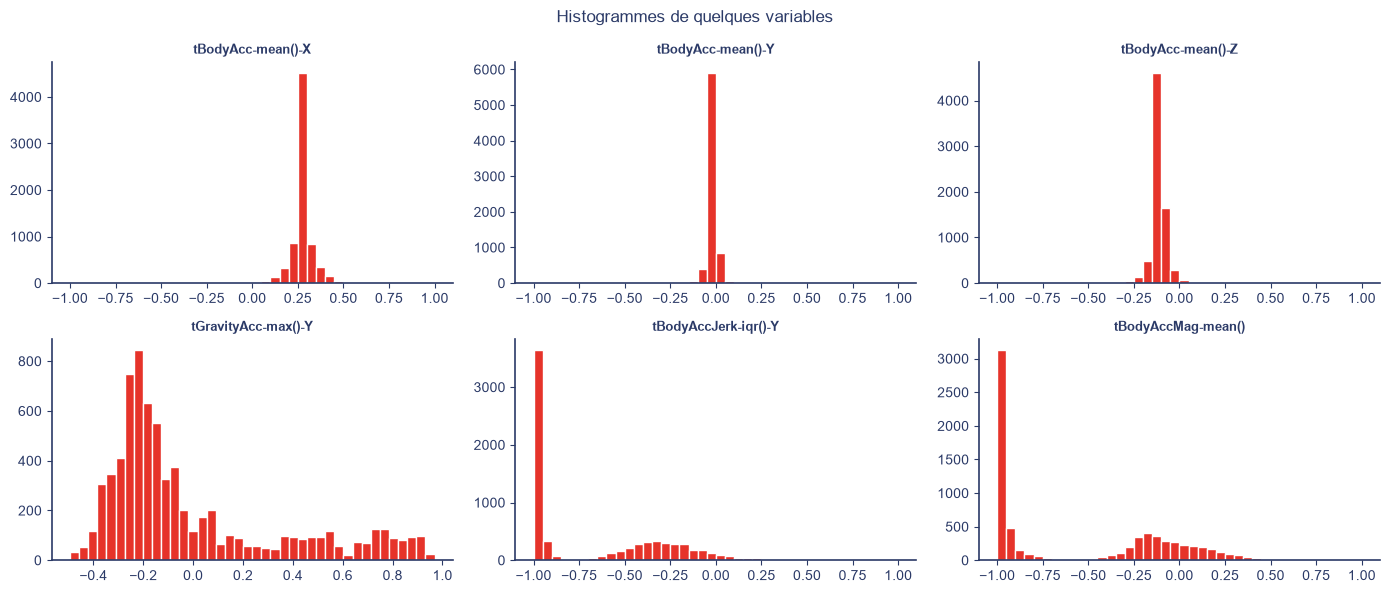

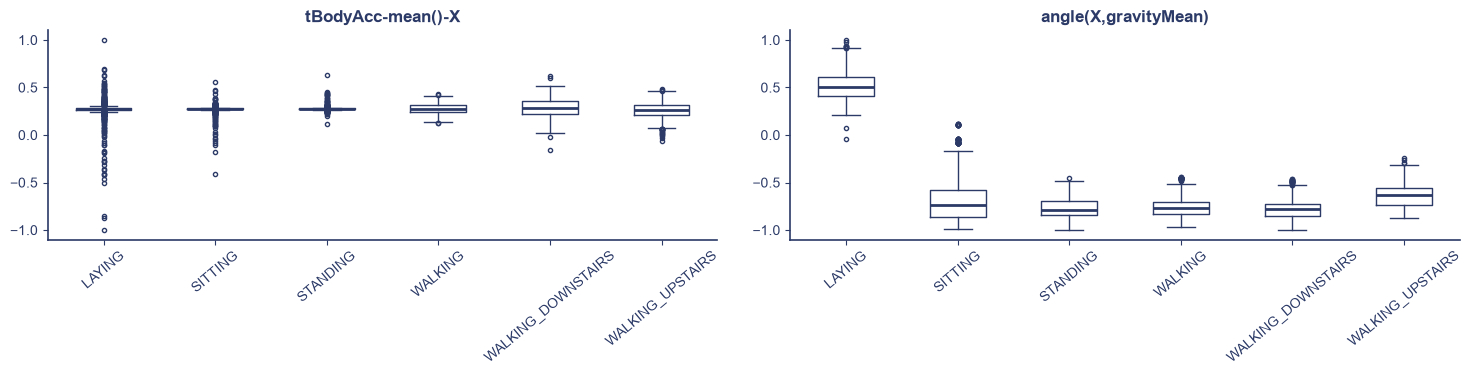

In [14]:
cols_h = [feature_cols[i] for i in [0, 1, 2, 50, 100, 200]]
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, c in zip(axes.ravel(), cols_h):
    ax.hist(train_df[c], bins=40, color=ROUGE, edgecolor=BLANC)
    ax.set_title(c[:35], fontsize=9)
plt.suptitle("Histogrammes de quelques variables"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, c in zip(axes, [feature_cols[0], feature_cols[-3]]):
    train_df.boxplot(column=c, by="Activity", ax=ax, rot=40, grid=False,
                 color=dict(boxes=BLEU, whiskers=BLEU, medians=BLEU, caps=BLEU),
                 flierprops=dict(marker="o", markeredgecolor=BLEU, markerfacecolor="none", markersize=3),
                 medianprops=dict(linewidth=2, color=BLEU))
    ax.set_title(c[:40]); ax.set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()

rq: angle(X,gravityMean): Sur chaque fenêtre, on calcule le vecteur gravité moyen (ses trois composantes), puis l’angle entre l’axe X du téléphone et ce vecteur. Cela dit comment le téléphone est orienté par rapport à la verticale. Couché, l’orientation est très différente de celle des autres postures, d’où la séparation de LAYING.

### 3.4 Corrélations entre variables


paires avec |corrélation| > 0.95 : 2281 sur 157080 (1.5%)


C:\Users\ReMarkt\AppData\Local\Temp\ipykernel_17152\2969577791.py:78: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


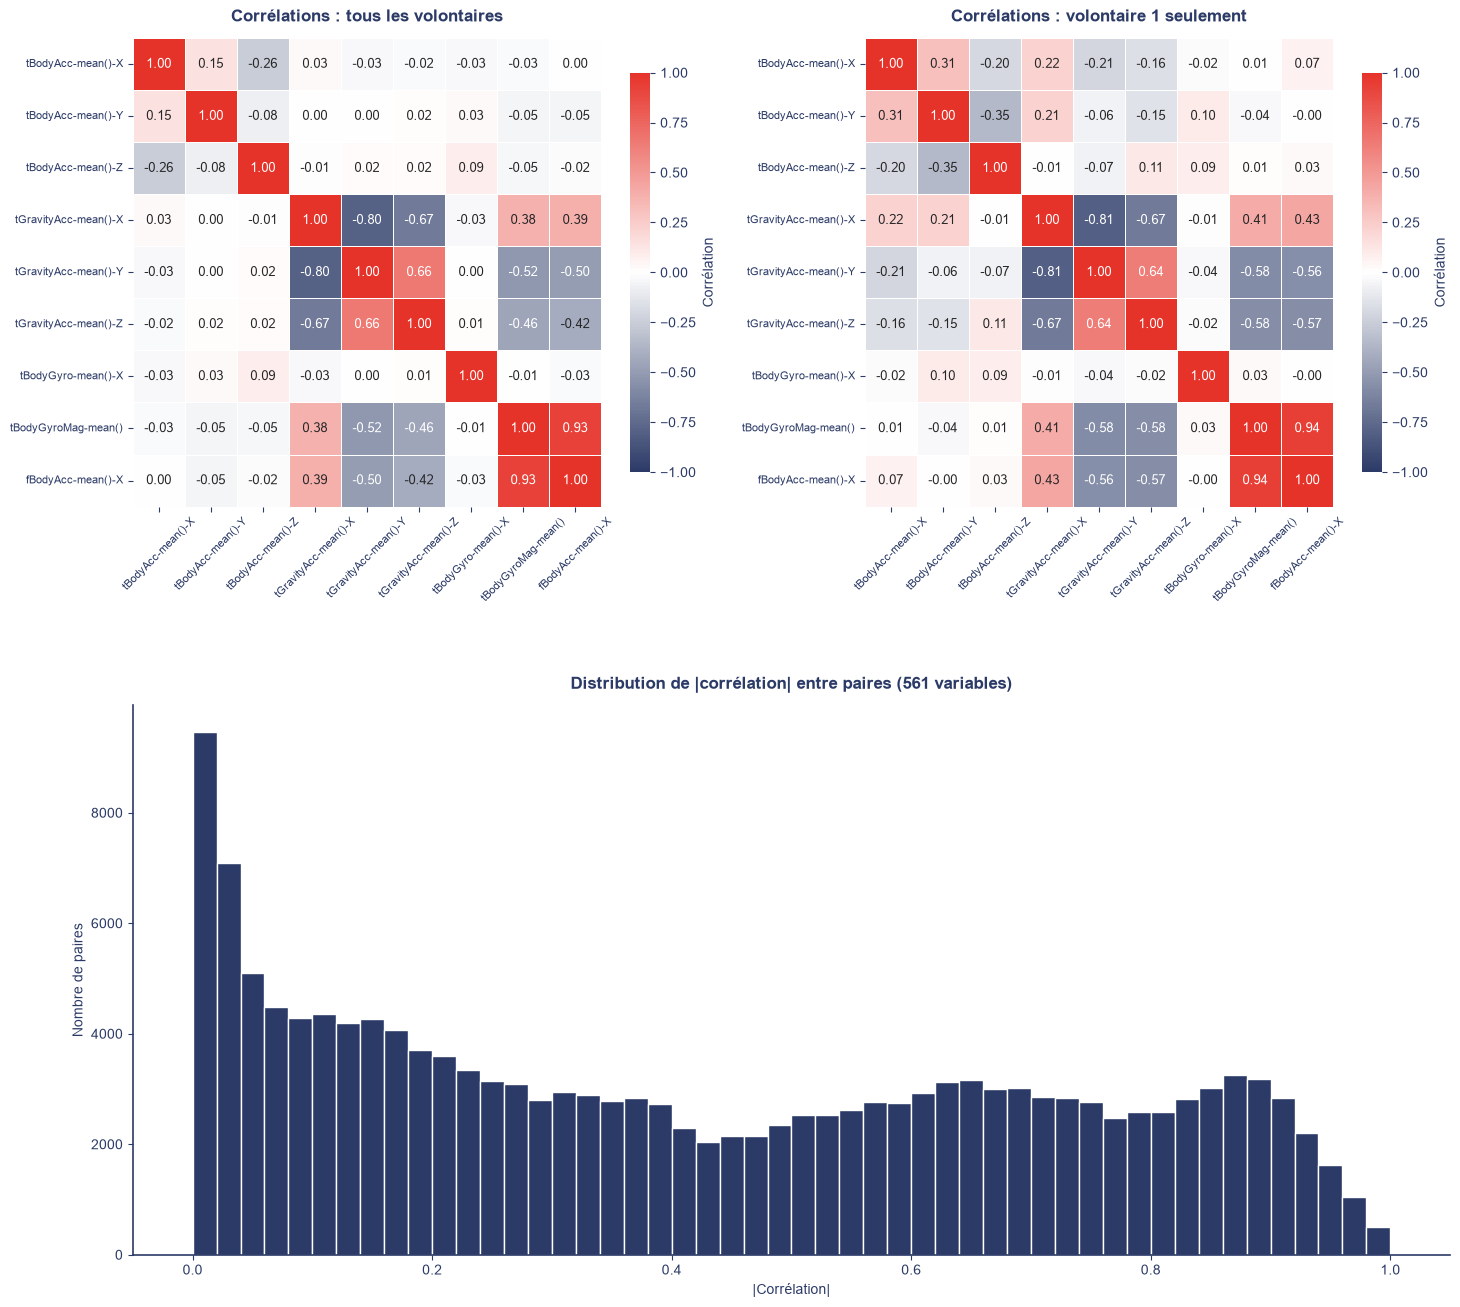

In [ ]:
# Volontaire pris comme exemple
target_subject = 1
subj_df = train_df[train_df["subject"] == target_subject]

# Quelques variables représentatives
sample_features = [
    "tBodyAcc-mean()-X", "tBodyAcc-mean()-Y", "tBodyAcc-mean()-Z",
    "tGravityAcc-mean()-X", "tGravityAcc-mean()-Y", "tGravityAcc-mean()-Z",
    "tBodyGyro-mean()-X", "tBodyGyroMag-mean()", "fBodyAcc-mean()-X",
]

corr_all = train_df[sample_features].corr()
corr_subj = subj_df[sample_features].corr()

# Corrélations entre toutes les paires de variables
corr_full = train_df[feature_cols].corr().to_numpy()
iu = np.triu_indices_from(corr_full, k=1)
high = np.abs(corr_full[iu]) > 0.95

print(
    f"paires avec |corrélation| > 0.95 : "
    f"{high.sum()} sur {len(iu[0])} ({high.mean():.1%})"
)

# plots 
fig = plt.figure(figsize=(17, 16))

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1, 1.1],
    hspace=0.35,
    wspace=0.25
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

for ax, corr, titre in [
    (ax1, corr_all, "Corrélations : tous les volontaires"),
    (ax2, corr_subj, f"Corrélations : volontaire {target_subject} seulement")
]:
    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap=CMAP_DIV,
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.5,
        linecolor=BLANC,
        cbar_kws={"label": "Corrélation", "shrink": 0.8},
        annot_kws={"size": 9},
        ax=ax
    )

    ax.set_title(titre, pad=12)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)

# Histogramme
ax3.hist(
    np.abs(corr_full[iu]),
    bins=50,
    color=BLEU,
    edgecolor=BLANC
)

ax3.set_title(
    "Distribution de |corrélation| entre paires (561 variables)",
    pad=12
)
ax3.set_xlabel("|Corrélation|")
ax3.set_ylabel("Nombre de paires")

plt.tight_layout()
plt.show()

### 3.5 Encodage de la cible et préparation des tableaux
Les réseaux travaillent avec des nombres : on associe un entier de 0 à 5 à chaque activité (ordre alphabétique). La colonne `subject` n'est **pas** une entrée du modèle : on la garde à part, car elle servira au découpage de la partie suivante.

In [13]:
class_to_idx = {c: i for i, c in enumerate(classes)}
print(class_to_idx)

X_all = train_df[feature_cols].to_numpy(dtype=np.float32)
y_all = train_df["Activity"].map(class_to_idx).to_numpy()
subject_all = train_df["subject"].to_numpy()

print("X_all :", X_all.shape, X_all.dtype, "| y_all :", y_all.shape, y_all.dtype)
print("exemples par classe :", np.bincount(y_all))

{'LAYING': 0, 'SITTING': 1, 'STANDING': 2, 'WALKING': 3, 'WALKING_DOWNSTAIRS': 4, 'WALKING_UPSTAIRS': 5}
X_all : (7352, 561) float32 | y_all : (7352,) int64
exemples par classe : [1407 1286 1374 1226  986 1073]


 rq: La colonne `subject` sert uniquement à **découper** les données en train et validation par volontaires entiers.

### Bilan du prétraitement
- **Échelle** : les 561 variables sont déjà comprises dans [-1, 1], mais ne sont ni centrées ni réduites. On les **standardise**, avec la moyenne et l'écart-type calculés sur le train uniquement, pour améliorer le conditionnement de l'optimisation.
- **Encodage** : la cible `Activity` est transformée en entiers de 0 à 5 ( LAYING 0, SITTING 1, STANDING 2, WALKING 3, WALKING_DOWNSTAIRS 4, WALKING_UPSTAIRS 5), au type `int64` attendu par `CrossEntropyLoss`. Les entrées sont en `float32`.
- **Colonnes** : aucune valeur manquante, aucune ligne dupliquée, aucune variable non numérique. `subject` est exclue des entrées et gardée pour le découpage ; `Activity` est la cible.
- **Redondance** : forte (beaucoup de paires de variables avec |corrélation| > 0,9) mais on conserve toutes les variables : le réseau s'en accommode et la régularisation limitera le surapprentissage. Une sélection de variables est envisagée en ouverture.
- **Classes** : à peu près équilibrées (de 13,4 % à 19,1 % dans le train, 7352 fenêtres au total), proportions proches du test. On suivra donc l'accuracy et le F1 macro, ainsi que le F1 par classe.